<hr style="border:2px solid #CC00FF;">

<div style="display:flex; justify-content:center; align-items:center; gap:25px; flex-wrap:nowrap; margin:5px 0;">
    <a href="https://medellin.unal.edu.co" target="_blank">
        <img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcR9ItLTT_F-3Q30cu7ZCCoKmuFGBt22pe7pNA"
             style="height:60px; width:auto; max-width:150px; object-fit:contain;" alt="Logo UNAL">
    </a>
    <a href="https://minaslap.net/?redirect=0" target="_blank">
        <img src="https://minaslap.net/pluginfile.php/1/core_admin/logo/0x200/1770226238/Logo%20MinasLAP-3%20%281%29.png"
             style="height:60px; width:auto; max-width:180px; object-fit:contain;" alt="Logo MinasLAP">
    </a>
    <a href="https://micampus.unal.edu.co" target="_blank">
        <img src="https://micampus.unal.edu.co/pluginfile.php/1/theme_almondb/sliderimage1/1788871931/Slider_1.png"
             style="height:60px; width:auto; max-width:200px; object-fit:contain;" alt="Logo MiCampus">
    </a>
</div>

<h2 align="center" style="font-size:1.4em; margin:6px 0;">Deep Learning 2026-2S</h2>
<h3 align="center" style="font-size:1.05em; margin:4px 0;">Follow Up 2 </h3>
<h4 align="center" style="font-size:0.9em; margin:4px 0; color:#555;">Semana 2</h4>

<p align="center" style="font-size:0.82em; line-height:1.3; margin:6px 0;">
Departamento de Ciencias de la Computación y de la Decisión<br>
Facultad de Minas · Universidad Nacional de Colombia<br>
Docente: John R. Ballesteros
</p>

<hr style="border:1px solid #CC00FF; margin:8px 0;">

<p style="font-size:0.78em; line-height:1.35; margin:4px 0;"><b>Equipo de trabajo:</b></p>

<table style="width:100%; font-size:0.72em; line-height:1.25; border-collapse:collapse;">
  <tr>
    <td style="padding:2px 6px;">• Kevin F. Hidalgo Higuita</td>
    <td style="padding:2px 6px;">📧 <i>kfhidalgoh@unal.edu.co</i></td>
  </tr>
</table>

<p align="center" style="font-size:0.75em; margin:8px 0 0 0;">
📅 03 de Noviembre de 2026 ·
<a href="https://github.com/KevinHidalgoDS/deep-learning-labs">
  <img src="https://img.shields.io/badge/repository-GitHub-181717.svg" alt="GitHub Repo" style="vertical-align:middle;">
</a>
</p>

<p align="center" style="font-size:0.68em; color:#777; margin:4px 0 0 0;">
<i>Nota: el tema del navegador puede afectar la visualización de la presentación.</i>
</p>

# Importación de librerías y configuración inicial

In [1]:
# -*- coding: utf-8 -*-
"""Configuración e importación de dependencias del cuaderno."""

import os
import random
import sys
import time
import urllib.request
from pathlib import Path

import keras_tuner as kt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from src.config import PROJECT_PATH
from src.utils import logger as log
from tensorflow import keras
from tensorflow.keras import layers

logger = log.LOGGER
config = log.CONFIG

# El logger del proyecto ya aporta manejadores y formato con fecha y nivel.
plt.style.use("ggplot")
rng = np.random.default_rng(42)

logger.info("Python %s en %s", sys.version, sys.platform)
logger.debug("Logger del proyecto configurado para el cuaderno.")

2026-11-04 10:09:03 [INFO] Python 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)] en win32
2026-11-04 10:09:03 [DEBUG] Logger del proyecto configurado para el cuaderno.


## Carga de datos

In [2]:
# Resolver la ubicación del archivo de datos.
file_path = Path(config.paths.data.raw) / "kc_house_data_yr.xlsx"
if not file_path.exists():
    alternate_path = PROJECT_PATH / config.paths.data.raw / "kc_house_data_yr.xlsx"
    if alternate_path.exists():
        logger.warning(
            "No se encontró el archivo en la ruta configurada; se usará %s", alternate_path
        )
        file_path = alternate_path

# Cargar y validar el conjunto de datos.
try:
    if not file_path.is_file():
        raise FileNotFoundError(f"No se encontró el archivo de datos: {file_path}")
    housePrices = pd.read_excel(file_path)
except (FileNotFoundError, ImportError, OSError, ValueError):
    logger.exception("Error al cargar los datos desde %s", file_path)
    raise

if housePrices.empty:
    logger.error("El archivo de datos no contiene registros.")
    raise ValueError("El conjunto de datos está vacío.")
if "price" not in housePrices.columns:
    logger.error("Falta la columna objetivo obligatoria 'price'.")
    raise ValueError("El conjunto de datos debe incluir la columna 'price'.")
if not housePrices.dtypes.map(pd.api.types.is_numeric_dtype).all():
    logger.error("El conjunto de datos contiene columnas no numéricas.")
    raise TypeError("Todas las características y el objetivo deben ser numéricos.")
if not np.isfinite(housePrices.to_numpy(dtype=np.float64, na_value=np.nan)).all():
    logger.error("El conjunto de datos contiene valores nulos o no finitos.")
    raise ValueError("El conjunto de datos no puede contener valores nulos o no finitos.")

logger.info("Datos cargados correctamente: %s filas y %s columnas.", *housePrices.shape)
housePrices.head()

2026-11-04 10:09:03 [WARNING] No se encontró el archivo en la ruta configurada; se usará D:\deep-learning-labs\data\raw\kc_house_data_yr.xlsx
2026-11-04 10:09:05 [INFO] Datos cargados correctamente: 21613 filas y 21 columnas.


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013,221900,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209,538000,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225,180000,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209,604000,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218,510000,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


# Modelado de red neuronal profunda (DNN) para predicción de precios de casas

## Características y objetivo

In [3]:
# Separar las características de la variable objetivo.
try:
    X = housePrices.drop(columns="price").to_numpy(dtype=np.float64)
    y = housePrices["price"].to_numpy(dtype=np.float64)
except (KeyError, TypeError, ValueError):
    logger.exception("No fue posible separar las características y el objetivo.")
    raise

if X.ndim != 2 or X.shape[0] != y.shape[0] or X.shape[1] == 0:
    logger.error("Dimensiones incompatibles: características %s, objetivo %s.", X.shape, y.shape)
    raise ValueError("Las características y el objetivo deben tener filas compatibles.")
logger.debug("Formas de entrada: X=%s, y=%s", X.shape, y.shape)

2026-11-04 10:09:05 [DEBUG] Formas de entrada: X=(21613, 20), y=(21613,)


## Train-test split

In [4]:
# Dividir los datos para entrenamiento y evaluación.
try:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
except ValueError:
    logger.exception("No fue posible dividir los datos en entrenamiento y prueba.")
    raise
logger.info("División de datos completada: %s filas de entrenamiento.", X_train.shape[0])

2026-11-04 10:09:05 [INFO] División de datos completada: 17290 filas de entrenamiento.


## Escalamiento de características

In [5]:
# Ajustar el escalador solo con los datos de entrenamiento para evitar fugas de información.
scaler = StandardScaler()
try:
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
except (TypeError, ValueError):
    logger.exception("Error al escalar las características.")
    raise
logger.debug("Escalamiento completado: X_train=%s, X_test=%s", X_train.shape, X_test.shape)

2026-11-04 10:09:05 [DEBUG] Escalamiento completado: X_train=(17290, 20), X_test=(4323, 20)


## Definición de la arquitectura de la red neuronal profunda (DNN)

In [6]:
def model_builder(hp: kt.HyperParameters) -> keras.Sequential:
    """Construye una red neuronal con hiperparámetros configurables.

    Args:
        hp: Objeto de Keras Tuner para definir y consultar hiperparámetros.

    Returns:
        keras.Sequential: Modelo de regresión compilado.

    Raises:
        AttributeError: Si el objeto de hiperparámetros no implementa la API esperada.
        TypeError: Si Keras recibe un parámetro de tipo incorrecto.
        ValueError: Si hp es None o Keras rechaza la configuración del modelo.

    Examples:
        >>> hiperparametros = kt.HyperParameters()
        >>> modelo = model_builder(hiperparametros)
        >>> modelo.loss
        'mse'
    """
    if hp is None:
        logger.error("El objeto de hiperparámetros no puede ser None.")
        raise ValueError("El objeto de hiperparámetros no puede ser None.")

    try:
        # Crear capas ocultas con unidades y regularización opcional ajustables.
        model = keras.Sequential()
        for i in range(hp.Int("num_layers", 1, 3)):
            model.add(
                layers.Dense(
                    units=hp.Int(f"units_{i}", min_value=32, max_value=256, step=32),
                    activation="relu",
                )
            )
            if hp.Boolean(f"dropout_{i}"):
                model.add(
                    layers.Dropout(
                        rate=hp.Choice(f"dropout_rate_{i}", [0.2, 0.3, 0.4])
                    )
                )

        # Añadir salida de regresión y compilar el modelo.
        model.add(layers.Dense(1, activation="linear"))
        learning_rate = hp.Choice("learning_rate", [1e-2, 1e-3, 1e-4])
        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
            loss="mse",
            metrics=["mae"],
        )
    except (AttributeError, TypeError, ValueError):
        logger.exception("No fue posible construir el modelo con los hiperparámetros dados.")
        raise

    logger.debug("Modelo compilado con tasa de aprendizaje %s.", learning_rate)
    return model

## Configuración del tuner de Keras Tuner

In [7]:
# Configurar la búsqueda aleatoria de hiperparámetros.
try:
    tuner = kt.RandomSearch(
        model_builder,
        objective="val_mae",
        max_trials=5,
        executions_per_trial=2,
        directory="house_tuning",
        project_name="kc_house_regression",
    )
except (ImportError, OSError, ValueError):
    logger.exception("No fue posible configurar la búsqueda de hiperparámetros.")
    raise
logger.info("Búsqueda de hiperparámetros configurada.")

2026-11-04 10:09:06 [INFO] Búsqueda de hiperparámetros configurada.


Reloading Tuner from house_tuning\kc_house_regression\tuner0.json


## Búsqueda de hiperparámetros

In [8]:
# Ejecutar la búsqueda de hiperparámetros.
try:
    tuner.search(X_train, y_train, epochs=50, validation_split=0.2, verbose=1)
except (RuntimeError, TypeError, ValueError, tf.errors.OpError):
    logger.exception("La búsqueda de hiperparámetros falló.")
    raise
logger.info("Búsqueda de hiperparámetros finalizada.")

2026-11-04 10:09:06 [INFO] Búsqueda de hiperparámetros finalizada.


## Resultados de la búsqueda de hiperparámetros

In [9]:
# Obtener el mejor conjunto encontrado y validar que exista.
try:
    best_hps_list = tuner.get_best_hyperparameters(num_trials=1)
    if not best_hps_list:
        raise ValueError("La búsqueda no produjo hiperparámetros válidos.")
    best_hps = best_hps_list[0]
except (IndexError, RuntimeError, ValueError):
    logger.exception("No se pudieron recuperar los mejores hiperparámetros.")
    raise
logger.info("Mejores hiperparámetros recuperados.")

2026-11-04 10:09:06 [INFO] Mejores hiperparámetros recuperados.


In [10]:
# Mostrar la configuración seleccionada para facilitar su revisión.
print("Mejores hiperparámetros:")
print(f"Capas: {best_hps.get('num_layers')}")
for i in range(best_hps.get('num_layers')):
    print(
        f"Unidades capa {i}: {best_hps.get(f'units_{i}')}, "
        f"Dropout: {best_hps.get(f'dropout_{i}')}"
    )
print(f"Tasa de aprendizaje: {best_hps.get('learning_rate')}")

Mejores hiperparámetros:
Capas: 1
Unidades capa 0: 64, Dropout: False
Tasa de aprendizaje: 0.01


## Entrenamiento del modelo con los mejores hiperparámetros

In [11]:
# Construir y entrenar el modelo definitivo.
try:
    model = tuner.hypermodel.build(best_hps)
    history = model.fit(X_train, y_train, validation_split=0.2, epochs=100, verbose=1)
except (RuntimeError, TypeError, ValueError, tf.errors.OpError):
    logger.exception("Error al construir o entrenar el modelo final.")
    raise
logger.info("Entrenamiento finalizado.")

2026-11-04 10:09:06 [DEBUG] Modelo compilado con tasa de aprendizaje 0.01.


Epoch 1/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 421560713216.0000 - mae: 536128.0625 - val_loss: 386620522496.0000 - val_mae: 526970.6875
Epoch 2/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 397701644288.0000 - mae: 520511.8125 - val_loss: 353439023104.0000 - val_mae: 503858.0312
Epoch 3/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 355476766720.0000 - mae: 491418.6875 - val_loss: 307285557248.0000 - val_mae: 469130.0625
Epoch 4/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 303930212352.0000 - mae: 452475.5312 - val_loss: 256565100544.0000 - val_mae: 426303.0000
Epoch 5/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 250952466432.0000 - mae: 407024.1875 - val_loss: 208039149568.0000 - val_mae: 378877.8438
Epoch 6/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 202472243200.0000 - mae: 358880.2812 - val_loss: 166258016256.0000 - val_mae: 330666.2500
Epoch 7/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 162079408128.0000 - mae: 313079.8

2026-11-04 10:10:20 [INFO] Entrenamiento finalizado.


## Evaluación del modelo

In [12]:
# Evaluar el modelo con el conjunto de prueba independiente.
try:
    test_loss, test_mae = model.evaluate(X_test, y_test)
except (RuntimeError, TypeError, ValueError, tf.errors.OpError):
    logger.exception("No fue posible evaluar el modelo con el conjunto de prueba.")
    raise
if not np.isfinite([test_loss, test_mae]).all():
    logger.error(
        "La evaluación produjo métricas no finitas: pérdida=%s, MAE=%s.", test_loss, test_mae
    )
    raise ValueError("Las métricas de evaluación deben ser finitas.")
logger.info("Evaluación finalizada: pérdida=%s, MAE=%s.", test_loss, test_mae)
print(f"MAE de prueba: {test_mae}")

136/136 ━━━━━━━━━━━━━━━━━━━━ 0s 874us/step - loss: 36043911168.0000 - mae: 112688.4062


2026-11-04 10:10:20 [INFO] Evaluación finalizada: pérdida=36043911168.0, MAE=112688.40625.


MAE de prueba: 112688.40625


In [13]:
# Comparar experimentos con distintos números de pruebas.

trial_values = [3, 5, 8]

results = {}
histories = {}
all_trials = []

if not trial_values or any(not isinstance(value, int) or value <= 0 for value in trial_values):
    logger.error("La lista de pruebas debe contener enteros positivos.")
    raise ValueError("Los números de pruebas deben ser enteros positivos.")

for n_trials in trial_values:

    logger.info("Iniciando experimento con %s pruebas.", n_trials)
    print(f"\n{'='*50}")
    print(f"EXPERIMENTO CON {n_trials} PRUEBAS")
    print(f"{'='*50}")

    # Crear un tuner independiente para cada experimento.
    try:
        tuner = kt.RandomSearch(
            model_builder,
            objective="val_mae",
            max_trials=n_trials,
            executions_per_trial=2,
            directory="house_tuning",
            project_name=f"kc_house_{n_trials}_trials",
            overwrite=True,
        )
    except (ImportError, OSError, TypeError, ValueError):
        logger.exception("No fue posible configurar el experimento de %s pruebas.", n_trials)
        raise

    # Buscar la mejor configuración de hiperparámetros.
    try:
        tuner.search(
            X_train,
            y_train,
            epochs=50,
            validation_split=0.2,
            verbose=1,
        )
    except (RuntimeError, TypeError, ValueError, tf.errors.OpError):
        logger.exception("Falló la búsqueda para el experimento de %s pruebas.", n_trials)
        raise

    # Recopilar la métrica de validación de cada prueba.
    for trial in tuner.oracle.trials.values():
        try:
            validation_mae = trial.metrics.get_best_value("val_mae")
        except (KeyError, TypeError, ValueError):
            logger.exception(
                "No se pudo obtener el MAE de validación de la prueba %s.", trial.trial_id
            )
            raise
        all_trials.append(
            {
                "Number of trials": n_trials,
                "Trial": trial.trial_id,
                "Validation MAE": validation_mae,
            }
        )

    # Recuperar los mejores hiperparámetros y comprobar que existan.
    try:
        best_hps_list = tuner.get_best_hyperparameters(num_trials=1)
        if not best_hps_list:
            raise ValueError("La búsqueda no produjo hiperparámetros válidos.")
        best_hps = best_hps_list[0]
    except (IndexError, RuntimeError, ValueError):
        logger.exception("No se obtuvieron hiperparámetros para %s pruebas.", n_trials)
        raise

    print("\nMejores hiperparámetros:")
    print(f"Capas: {best_hps.get('num_layers')}")

    for i in range(best_hps.get('num_layers')):
        print(
            f"Unidades capa {i}: {best_hps.get(f'units_{i}')}, "
            f"Dropout: {best_hps.get(f'dropout_{i}')}"
        )

    print(f"Tasa de aprendizaje: {best_hps.get('learning_rate')}")

    # Construir y entrenar el modelo con la mejor configuración.
    try:
        model = tuner.hypermodel.build(best_hps)

        history = model.fit(
            X_train,
            y_train,
            validation_split=0.2,
            epochs=100,
            verbose=1,
        )
    except (RuntimeError, TypeError, ValueError, tf.errors.OpError):
        logger.exception("Falló el entrenamiento del experimento de %s pruebas.", n_trials)
        raise

    # Evaluar en el conjunto de prueba y validar las métricas obtenidas.
    try:
        loss, mae = model.evaluate(X_test, y_test, verbose=0)
    except (RuntimeError, TypeError, ValueError, tf.errors.OpError):
        logger.exception("Falló la evaluación del experimento de %s pruebas.", n_trials)
        raise
    if not np.isfinite([loss, mae]).all():
        logger.error("Se obtuvieron métricas no finitas en el experimento de %s pruebas.", n_trials)
        raise ValueError("Las métricas de evaluación deben ser finitas.")

    # Calcular métricas y guardar resultados del experimento.
    validation_values = [
        trial["Validation MAE"]
        for trial in all_trials
        if trial["Number of trials"] == n_trials
        and pd.notna(trial["Validation MAE"])
        and np.isfinite(trial["Validation MAE"])
    ]
    if not validation_values:
        logger.error("No hay MAE de validación válido para el experimento de %s pruebas.", n_trials)
        raise ValueError("No se encontraron métricas de validación finitas.")
    results[n_trials] = {
        "Best validation MAE": min(validation_values),
        "Test MAE": mae,
        "Best hyperparameters": best_hps.values,
    }

    histories[n_trials] = history

    logger.info("Experimento de %s pruebas finalizado.", n_trials)
    print(f"\nMejor MAE de validación: {results[n_trials]['Best validation MAE']:.2f}")
    print(f"MAE de prueba: {mae:.2f}")


# Construir y mostrar el detalle de resultados de cada prueba.
trials_df = pd.DataFrame(all_trials)
if trials_df.empty:
    logger.error("No se generaron resultados para la tabla de pruebas.")
    raise ValueError("La tabla de resultados de pruebas está vacía.")

for n_trials in trial_values:
    print(f"\nResultados para {n_trials} pruebas:")
    display(
        trials_df[trials_df["Number of trials"] == n_trials]
        .sort_values("Validation MAE")
        .reset_index(drop=True)
    )


# Crear un resumen comparativo de todos los experimentos.
summary_df = pd.DataFrame([
    {
        "Number of trials": n,
        "Best validation MAE": results[n]["Best validation MAE"],
        "Test MAE": results[n]["Test MAE"],
    }
    for n in trial_values
])

logger.info("Se generó el resumen comparativo de experimentos.")
print("\nRESUMEN DE EXPERIMENTOS")
display(summary_df)

2026-11-04 10:40:48 [DEBUG] Modelo compilado con tasa de aprendizaje 0.01.


Trial 8 Complete [00h 01m 21s]
val_mae: 71460.68359375

Best val_mae So Far: 71460.68359375
Total elapsed time: 00h 10m 46s

Mejores hiperparámetros:
Capas: 3
Unidades capa 0: 96, Dropout: False
Unidades capa 1: 160, Dropout: False
Unidades capa 2: 64, Dropout: False
Tasa de aprendizaje: 0.01
Epoch 1/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 81302773760.0000 - mae: 177467.1094 - val_loss: 30179606528.0000 - val_mae: 114588.3828
Epoch 2/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 32441800704.0000 - mae: 111188.6094 - val_loss: 28906420224.0000 - val_mae: 111442.0078
Epoch 3/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 30902464512.0000 - mae: 108458.5156 - val_loss: 28111294464.0000 - val_mae: 109590.1328
Epoch 4/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 29961566208.0000 - mae: 106982.7734 - val_loss: 27666731008.0000 - val_mae: 108552.6328
Epoch 5/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 29308891136.0000 - mae: 105938.9219 - val_loss: 2

2026-11-04 10:42:00 [INFO] Experimento de 8 pruebas finalizado.



Mejor MAE de validación: 71460.68
MAE de prueba: 77439.27

Resultados para 3 pruebas:


,Number of trials,Trial,Validation MAE
0,3,0,86245.910156
1,3,1,101580.347656
2,3,2,250948.460938



Resultados para 5 pruebas:


... (2 outputs left out)

,Number of trials,Trial,Validation MAE
0,8,7,71460.683594
1,8,2,102003.804688
2,8,4,105561.718750
3,8,0,111755.121094
4,8,6,113568.164062
5,8,1,131933.878906
6,8,5,136292.437500
7,8,3,431312.187500


2026-11-04 10:42:00 [INFO] Se generó el resumen comparativo de experimentos.



RESUMEN DE EXPERIMENTOS


,Number of trials,Best validation MAE,Test MAE
0,3,86245.910156,74765.437500
1,5,79044.945312,77648.914062
2,8,71460.683594,77439.265625


2026-11-04 10:42:00 [WARNING] La carpeta de figuras no existe en la ruta actual; se usará la del proyecto.


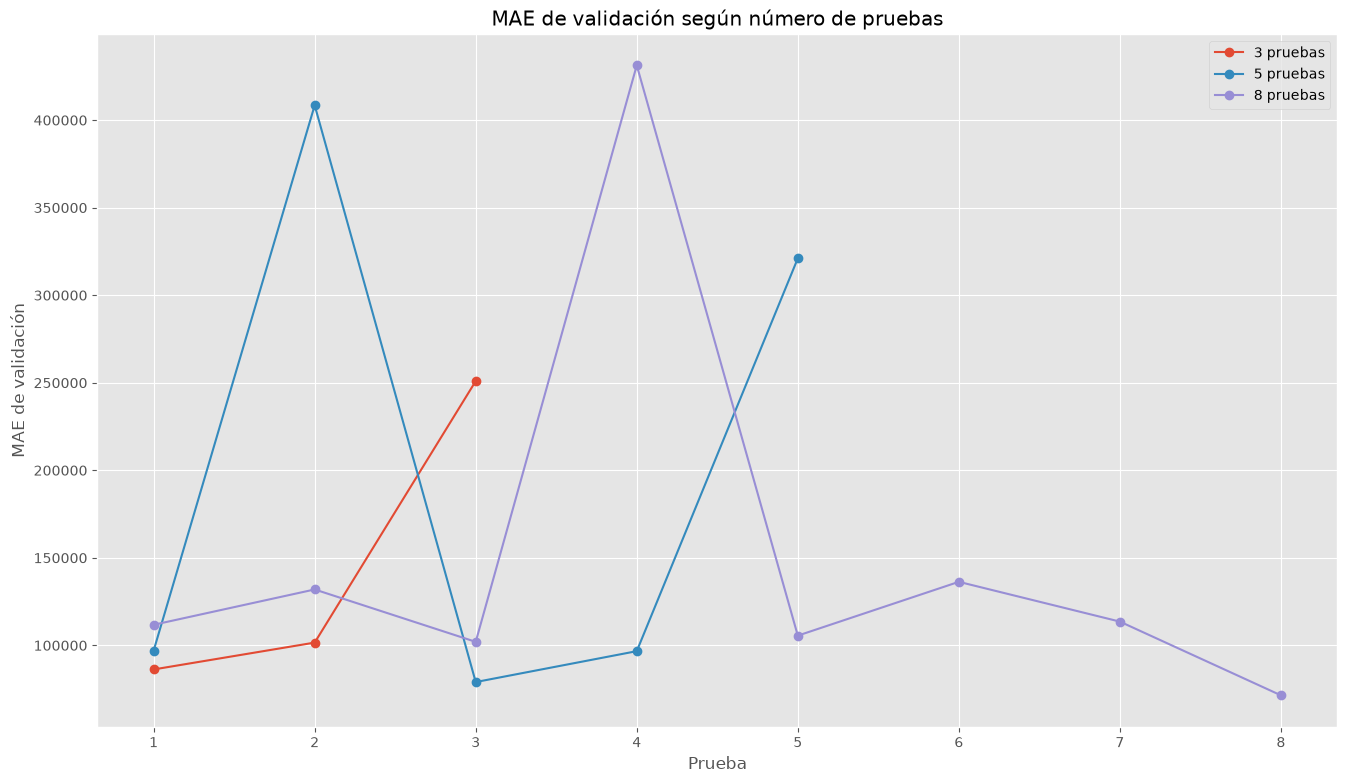

2026-11-04 10:42:01 [INFO] Gráfica de MAE de validación guardada en D:\deep-learning-labs\reports\figures\validation_mae_by_number_of_trials.png.


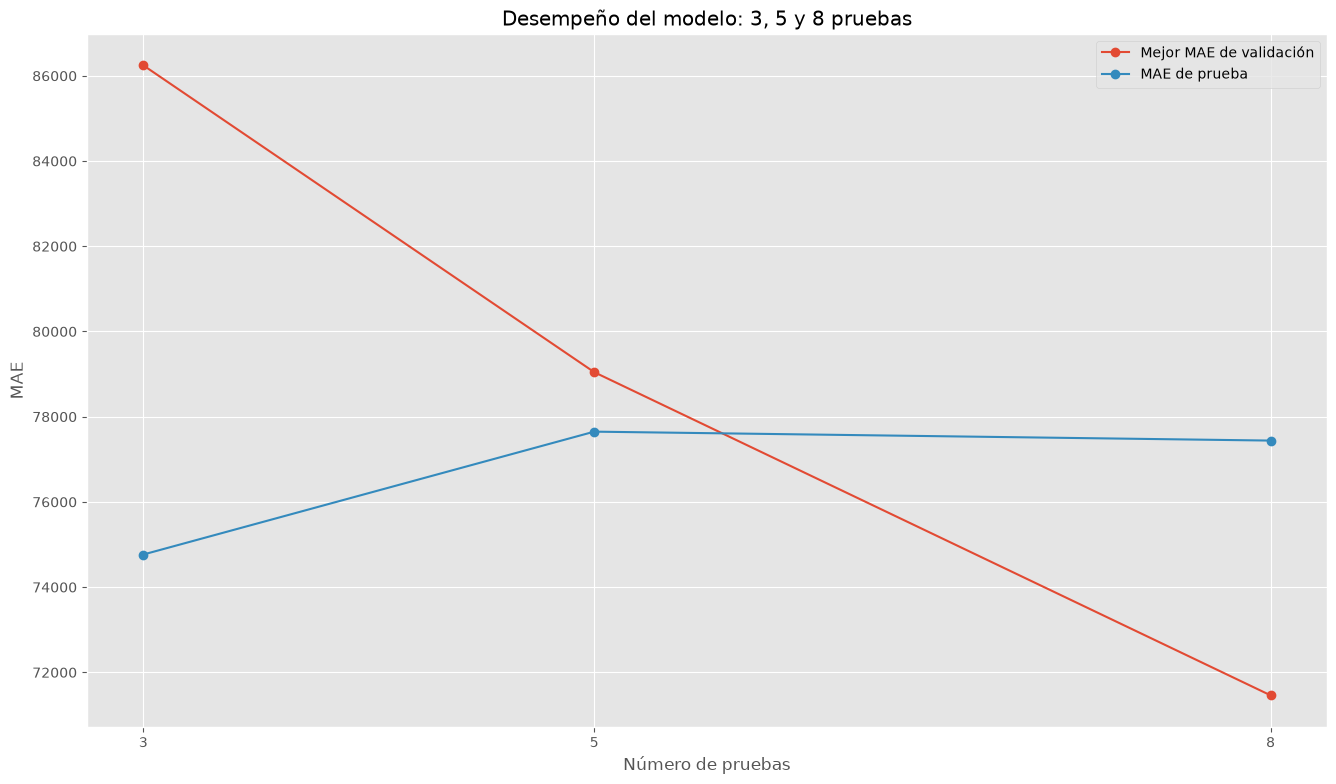

2026-11-04 10:42:01 [INFO] Gráfica comparativa guardada en D:\deep-learning-labs\reports\figures\model_performance_comparison.png.


In [14]:
# Validar resultados y resolver la carpeta de salida de las gráficas.
required_trial_columns = {"Number of trials", "Trial", "Validation MAE"}
required_summary_columns = {"Number of trials", "Best validation MAE", "Test MAE"}
if not required_trial_columns.issubset(trials_df.columns) or not required_summary_columns.issubset(
    summary_df.columns
):
    logger.error("Faltan columnas requeridas para generar las gráficas comparativas.")
    raise ValueError("Los resultados no contienen todas las columnas requeridas.")
if trials_df.empty or summary_df.empty:
    logger.error("No hay resultados suficientes para generar las gráficas comparativas.")
    raise ValueError("Las tablas de resultados no pueden estar vacías.")

figure_directory = Path(config.paths.reports.figures)
if not figure_directory.exists():
    logger.warning("La carpeta de figuras no existe en la ruta actual; se usará la del proyecto.")
    figure_directory = PROJECT_PATH / figure_directory
try:
    figure_directory.mkdir(parents=True, exist_ok=True)

    # Comparar el MAE de validación por prueba y configuración.
    validation_figure = figure_directory / "validation_mae_by_number_of_trials.png"
    plt.figure(figsize=(16, 9))
    for n in trial_values:
        subset = trials_df[trials_df["Number of trials"] == n].sort_values("Trial")
        plt.plot(
            range(1, len(subset) + 1),
            subset["Validation MAE"],
            marker="o",
            label=f"{n} pruebas",
        )
    plt.title("MAE de validación según número de pruebas")
    plt.xlabel("Prueba")
    plt.ylabel("MAE de validación")
    plt.legend()
    plt.grid(True)
    plt.savefig(validation_figure, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
    logger.info("Gráfica de MAE de validación guardada en %s.", validation_figure)

    # Comparar el mejor MAE de validación con el MAE de prueba.
    performance_figure = figure_directory / "model_performance_comparison.png"
    plt.figure(figsize=(16, 9))
    x = summary_df["Number of trials"]
    plt.plot(
        x,
        summary_df["Best validation MAE"],
        marker="o",
        label="Mejor MAE de validación",
    )
    plt.plot(x, summary_df["Test MAE"], marker="o", label="MAE de prueba")
    plt.title("Desempeño del modelo: 3, 5 y 8 pruebas")
    plt.xlabel("Número de pruebas")
    plt.ylabel("MAE")
    plt.xticks(trial_values)
    plt.legend()
    plt.grid(True)
    plt.savefig(performance_figure, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
    logger.info("Gráfica comparativa guardada en %s.", performance_figure)
except (OSError, TypeError, ValueError):
    plt.close("all")
    logger.exception("No fue posible generar o guardar las gráficas comparativas.")
    raise

2026-11-04 10:42:01 [WARNING] La carpeta de figuras no existe en la ruta actual; se usará la del proyecto.


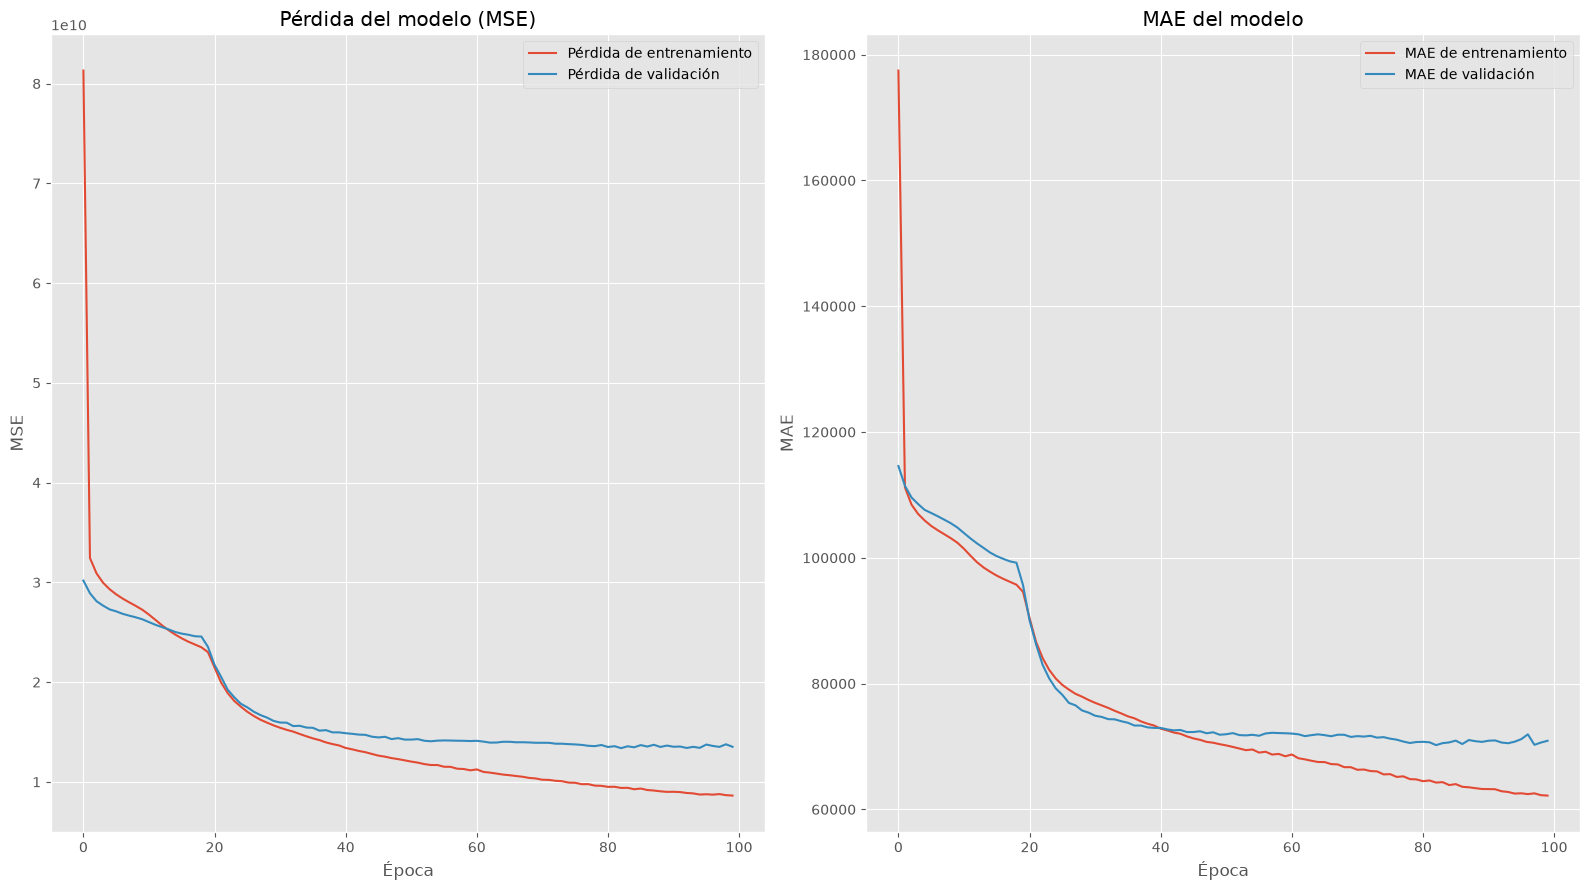

2026-11-04 10:42:02 [INFO] Gráfica del historial guardada en D:\deep-learning-labs\reports\figures\loss_mae_history.png.


In [15]:
# Validar el historial y graficar la evolución de las métricas.
if not isinstance(getattr(history, "history", None), dict):
    logger.error("El historial de entrenamiento no contiene un diccionario de métricas.")
    raise TypeError("El historial de entrenamiento no es válido.")
history_metrics = ("loss", "val_loss", "mae", "val_mae")
missing_metrics = [metric for metric in history_metrics if metric not in history.history]
if missing_metrics:
    logger.error("Faltan métricas en el historial: %s", missing_metrics)
    raise ValueError(f"El historial no contiene las métricas requeridas: {missing_metrics}")

figure_directory = Path(config.paths.reports.figures)
if not figure_directory.exists():
    logger.warning("La carpeta de figuras no existe en la ruta actual; se usará la del proyecto.")
    figure_directory = PROJECT_PATH / figure_directory
history_figure = figure_directory / "loss_mae_history.png"
try:
    figure_directory.mkdir(parents=True, exist_ok=True)

    # Mostrar la pérdida y el error absoluto medio por época.
    plt.figure(figsize=(16, 9))
    plt.subplot(1, 2, 1)
    plt.plot(history.history["loss"], label="Pérdida de entrenamiento")
    plt.plot(history.history["val_loss"], label="Pérdida de validación")
    plt.title("Pérdida del modelo (MSE)")
    plt.xlabel("Época")
    plt.ylabel("MSE")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["mae"], label="MAE de entrenamiento")
    plt.plot(history.history["val_mae"], label="MAE de validación")
    plt.title("MAE del modelo")
    plt.xlabel("Época")
    plt.ylabel("MAE")
    plt.legend()

    plt.tight_layout()
    plt.savefig(history_figure, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
except (OSError, TypeError, ValueError):
    plt.close("all")
    logger.exception("No fue posible generar o guardar la gráfica del historial.")
    raise
logger.info("Gráfica del historial guardada en %s.", history_figure)